In [88]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler, QuantileTransformer

from imblearn.over_sampling import RandomOverSampler

import tensorflow as tf
import tensorflow_hub as hub

import warnings
warnings.filterwarnings("ignore", category=UserWarning, module="tensorflow_hub")

In [97]:
import gdown

url = 'https://drive.google.com/uc?id=1fakbbdmqXLY8cyQdbd2kbHDQaN_XzCQb'

gdown.download(url, 'w-reviews.csv', quiet=False)

w = pd.read_csv('w-reviews.csv', usecols= ['country', 'description', 'points', 'price', 'variety', 'wry'])
display(w.head())

Downloading...
From: https://drive.google.com/uc?id=1fakbbdmqXLY8cyQdbd2kbHDQaN_XzCQb
To: /content/wine-reviews.csv
100%|██████████| 52.9M/52.9M [00:00<00:00, 128MB/s]


,country,description,points,price,variety,winery
1,Portugal,"This is ripe and fruity, a wine that is smooth...",87,15.0,Portuguese Red,Quinta dos Avidagos
2,US,"Tart and snappy, the flavors of lime flesh and...",87,14.0,Pinot Gris,Rainstorm
3,US,"Pineapple rind, lemon pith and orange blossom ...",87,13.0,Riesling,St. Julian
4,US,"Much like the regular bottling from 2012, this...",87,65.0,Pinot Noir,Sweet Cheeks
5,Spain,Blackberry and raspberry aromas show a typical...,87,15.0,Tempranillo-Merlot,Tandem


In [98]:
w = w.dropna(subset = ["description", "points"])

In [99]:
w.head()

,country,description,points,price,variety,winery
0,Italy,"Aromas include tropical fruit, broom, brimston...",87,NaN,White Blend,Nicosia
1,Portugal,"This is ripe and fruity, a wine that is smooth...",87,15.0,Portuguese Red,Quinta dos Avidagos
2,US,"Tart and snappy, the flavors of lime flesh and...",87,14.0,Pinot Gris,Rainstorm
3,US,"Pineapple rind, lemon pith and orange blossom ...",87,13.0,Riesling,St. Julian
4,US,"Much like the regular bottling from 2012, this...",87,65.0,Pinot Noir,Sweet Cheeks


In [100]:
w.isnull().sum()

,0
country,63
description,0
points,0
price,8996
variety,1
winery,0


In [101]:
w = w.dropna()

In [102]:
w.isnull().sum()

,0
country,0
description,0
points,0
price,0
variety,0
winery,0


In [103]:
w.shape

(120915, 6)

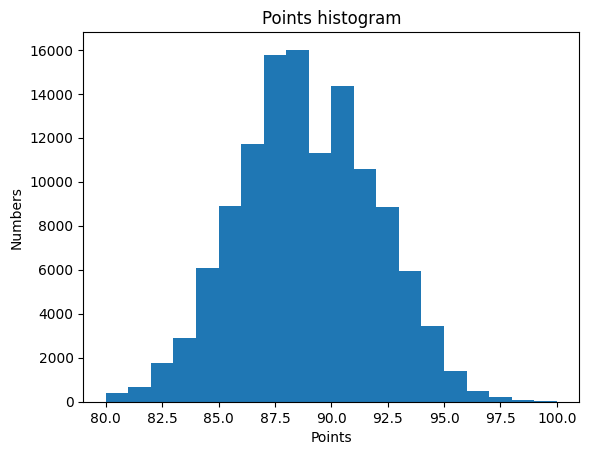

In [104]:
plt.hist(w.points, bins=20)
plt.title("Points histogram")
plt.xlabel("Points")
plt.ylabel("Numbers")
plt.show()

In [107]:
w['label'] = (w.points >= 90).astype(int)
w = w[["description", "label"]]

In [108]:
w.head()

,description,label
1,"This is ripe and fruity, a wine that is smooth...",0
2,"Tart and snappy, the flavors of lime flesh and...",0
3,"Pineapple rind, lemon pith and orange blossom ...",0
4,"Much like the regular bottling from 2012, this...",0
5,Blackberry and raspberry aromas show a typical...,0


In [109]:
train, val, test = np.split(w.sample(frac = 1), [ int(0.8*len(w)), int(0.9*len(w)) ])

/usr/local/lib/python3.13/dist-packages/numpy/_core/fromnumeric.py:54: FutureWarning: 'DataFrame.swapaxes' is deprecated and will be removed in a future version. Please use 'DataFrame.transpose' instead.
  return bound(*args, **kwds)


In [110]:
len(train), len(val), len(test)

(96732, 12091, 12092)

In [116]:
def df_to_dataset(dataframe, shuffle = True, batch_size = 1024):
  df = dataframe.copy()
  labels = df.pop('label')
  df = df['description']

  ds = tf.data.Dataset.from_tensor_slices((df, labels))

  if shuffle:
    ds = ds.shuffle(buffer_size = len(dataframe))
  ds = ds.batch(batch_size)
  ds = ds.prefetch(tf.data.AUTOTUNE)

  return ds

In [117]:
train_data = df_to_dataset(train)
val_data = df_to_dataset(val)
test_data = df_to_dataset(test)

##### Embedding + Model

In [119]:
embedding = "https://tfhub.dev/google/nnlm-en-dim50/2"

hub_layer = hub.KerasLayer(embedding, dtype = tf.string, trainable= True)

In [120]:
hub_layer(list(train_data)[0][0])

<tf.Tensor: shape=(1024, 50), dtype=float32, numpy=
array([[ 0.2916854 ,  0.01941469,  0.0018473 , ..., -0.04238557,
        -0.10405648, -0.12054334],
       [ 0.39038548, -0.41803995, -0.05876224, ...,  0.08053074,
         0.13817255, -0.01410262],
       [ 0.46324694, -0.05512348, -0.12414657, ..., -0.02435774,
         0.07616956, -0.01971362],
       ...,
       [ 0.40782765, -0.18810213,  0.18289259, ..., -0.08503453,
        -0.14507148, -0.13682511],
       [ 0.41747722, -0.36035755, -0.09552996, ...,  0.01639274,
        -0.10748155, -0.11555408],
       [ 0.34866008,  0.03877359,  0.11051917, ...,  0.05318374,
        -0.07638844,  0.06230196]], shape=(1024, 50), dtype=float32)>

In [124]:
model = tf.keras.Sequential([
   # tf.keras.layers.Input(shape=(), dtype=tf.string),
    hub_layer,
    tf.keras.layers.Dense(16, activation='relu'),
    tf.keras.layers.Dense(16, activation='relu'),
    tf.keras.layers.Dense(1, activation='sigmoid')
])

ValueError: Only instances of `keras.Layer` can be added to a Sequential model. Received: <tensorflow_hub.keras_layer.KerasLayer object at 0x78f08385a7b0> (of type <class 'tensorflow_hub.keras_layer.KerasLayer'>)

In [128]:
# Define a custom Keras Layer wrapper for the TF Hub layer to ensure compatibility with Keras 3
class HubEmbeddingLayer(tf.keras.layers.Layer):
    def __init__(self, hub_layer, **kwargs):
        super().__init__(**kwargs)
        self.hub_layer = hub_layer

    def call(self, inputs):
        # Ensure the inputs are treated as tensors by the legacy hub layer
        return self.hub_layer(inputs)

    def compute_output_shape(self, input_shape):
        return (input_shape[0], 50)

# Define the input layer
inputs = tf.keras.layers.Input(shape=(), dtype=tf.string)

# Pass the inputs through our custom embedding wrapper
embedded_outputs = HubEmbeddingLayer(hub_layer)(inputs)

# Add the subsequent Dense layers
x1 = tf.keras.layers.Dense(16, activation='relu')(embedded_outputs)
x2 = tf.keras.layers.Dense(16, activation='relu')(x1)
outputs = tf.keras.layers.Dense(1, activation='sigmoid')(x2)

# Define the final Keras Functional Model
model = tf.keras.Model(inputs=inputs, outputs=outputs)

# Display the model summary
model.summary()

Model: "functional_6"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ input_layer_10 (InputLayer)     │ (None)                 │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ hub_embedding_layer             │ (None, 50)             │             0 │
│ (HubEmbeddingLayer)             │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_24 (Dense)                │ (None, 16)             │           816 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_25 (Dense)                │ (None, 16)             │           272 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_26 (Dense)                │ (None, 1)              │            17 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 1,105 (4.32 KB)

 Trainable params: 1,105 (4.32 KB)

 Non-trainable params: 0 (0.00 B)

In [129]:
model.compile(
    optimizer = tf.keras.optimizers.Adam(learning_rate=0.001),
    loss = tf.keras.losses.BinaryCrossentropy(),
    metrics = ['accuracy']
)

### FeedForward Neural Network

In [138]:
url2 = 'https://drive.google.com/uc?id=1thSxj95Tfgz6I1KOFsmXz4OHv8FcLHk4'

gdown.download(url2, 'diabets.csv', quiet=False)

d = pd.read_csv('diabets.csv', engine="python", )
display(d.head())

Downloading...
From: https://drive.google.com/uc?id=1thSxj95Tfgz6I1KOFsmXz4OHv8FcLHk4
To: /content/diabets.csv
100%|██████████| 23.9k/23.9k [00:00<00:00, 47.9MB/s]


,Pregnancies,Glucose,BloodPressure,SkinThickness,Insulin,BMI,DiabetesPedigreeFunction,Age,Outcome
0,6,148,72,35,0,33.6,0.627,50,1
1,1,85,66,29,0,26.6,0.351,31,0
2,8,183,64,0,0,23.3,0.672,32,1
3,1,89,66,23,94,28.1,0.167,21,0
4,0,137,40,35,168,43.1,2.288,33,1


In [139]:
d.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 768 entries, 0 to 767
Data columns (total 9 columns):
 #   Column                    Non-Null Count  Dtype  
---  ------                    --------------  -----  
 0   Pregnancies               768 non-null    int64  
 1   Glucose                   768 non-null    int64  
 2   BloodPressure             768 non-null    int64  
 3   SkinThickness             768 non-null    int64  
 4   Insulin                   768 non-null    int64  
 5   BMI                       768 non-null    float64
 6   DiabetesPedigreeFunction  768 non-null    float64
 7   Age                       768 non-null    int64  
 8   Outcome                   768 non-null    int64  
dtypes: float64(2), int64(7)
memory usage: 54.1 KB


In [140]:
d.columns

Index(['Pregnancies', 'Glucose', 'BloodPressure', 'SkinThickness', 'Insulin',
       'BMI', 'DiabetesPedigreeFunction', 'Age', 'Outcome'],
      dtype='object')

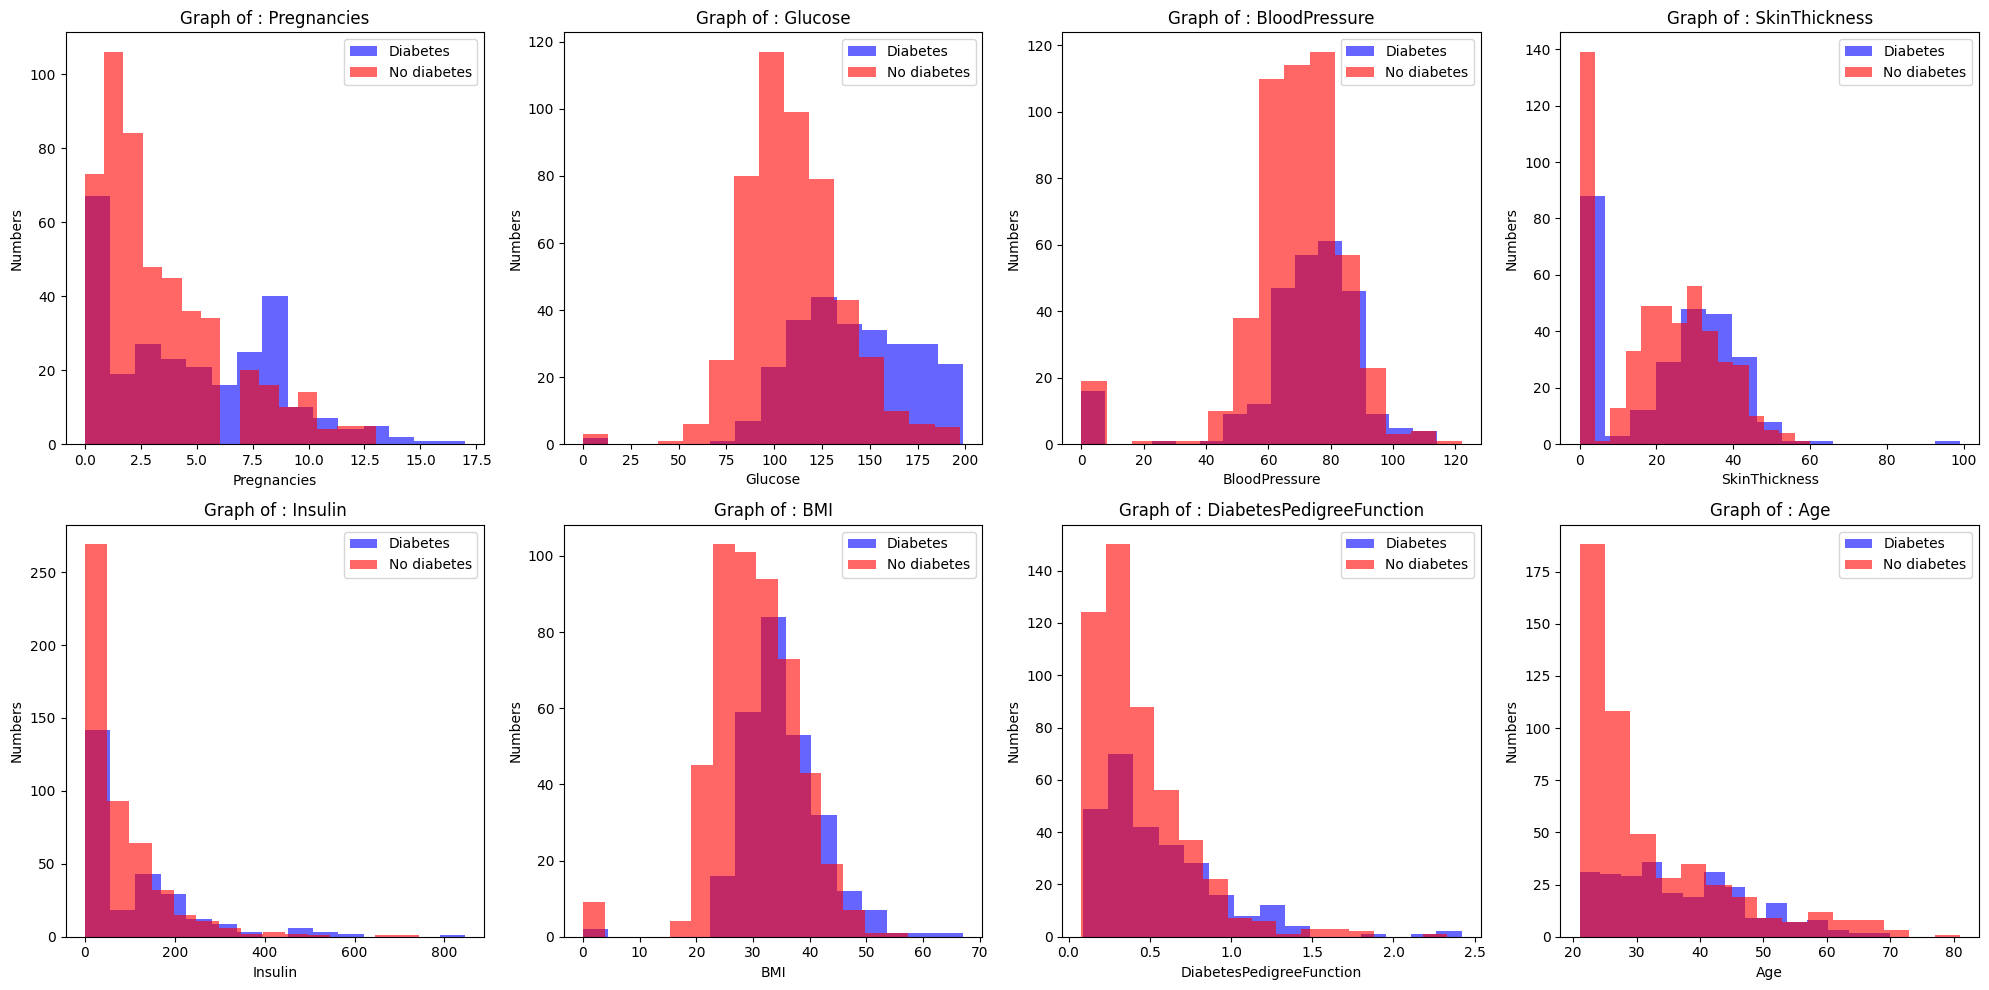

In [141]:
features = d.columns[:-1]

# Create a 2x4 grid layout for the 8 graphs
fig, axes = plt.subplots(nrows=2, ncols=4, figsize=(20, 10))
axes = axes.flatten()  # Flatten the 2D grid to 1D array for easier iteration

for i, label in enumerate(features):
    ax = axes[i]
    ax.hist(d[d['Outcome'] == 1][label], color='blue', alpha=0.6, label='Diabetes', bins=15)
    ax.hist(d[d['Outcome'] == 0][label], color='red', alpha=0.6, label='No diabetes', bins=15)

    ax.set_title(f"Graph of : {label}")
    ax.set_ylabel("Numbers")
    ax.set_xlabel(label)
    ax.legend()

plt.tight_layout()
plt.show()

In [142]:
x = d.drop(['Outcome'], axis=1)
y = d['Outcome']

In [143]:
x = StandardScaler().fit_transform(x)
y = StandardScaler().fit_transform(y.values.reshape(-1, 1))

print(x.shape)
print(y.shape)

(768, 8)
(768, 1)


In [144]:
x = QuantileTransformer().fit_transform(x)
y = QuantileTransformer().fit_transform(y)

x.shape, y.shape

/usr/local/lib/python3.13/dist-packages/sklearn/preprocessing/_data.py:2829: UserWarning: n_quantiles (1000) is greater than the total number of samples (768). n_quantiles is set to n_samples.
  warnings.warn(
/usr/local/lib/python3.13/dist-packages/sklearn/preprocessing/_data.py:2829: UserWarning: n_quantiles (1000) is greater than the total number of samples (768). n_quantiles is set to n_samples.
  warnings.warn(


((768, 8), (768, 1))

In [145]:
x, y = RandomOverSampler().fit_resample(x, y)

In [146]:
x_train, x_temp, y_train, y_temp = train_test_split(x, y, test_size= 0.2, random_state= 2)
x_valid, x_test, y_valid, y_test = train_test_split(x_temp, y_temp, test_size= 0.3, random_state= 2)

In [147]:
model = tf.keras.Sequential([
    tf.keras.layers.Dense(16, activation='relu'),
    tf.keras.layers.Dense(16, activation='relu'),
    tf.keras.layers.Dense(1, activation='sigmoid')
])

In [148]:
model.compile(
    optimizer = tf.keras.optimizers.Adam(learning_rate = 0.001),
    loss = tf.keras.losses.BinaryCrossentropy(),
    metrics = ['accuracy']
)

In [149]:
model.evaluate(x_train, y_train)

25/25 ━━━━━━━━━━━━━━━━━━━━ 1s 5ms/step - accuracy: 0.5063 - loss: 0.7295


[0.7295200824737549, 0.5062500238418579]

In [150]:
model.evaluate(x_valid, y_valid)

5/5 ━━━━━━━━━━━━━━━━━━━━ 1s 56ms/step - accuracy: 0.4429 - loss: 0.7500


[0.7500485181808472, 0.44285714626312256]

In [151]:
model.fit(
    x_train, y_train,
    batch_size = 16,
    epochs = 20,
    validation_data = (x_valid, y_valid)
)

Epoch 1/20
50/50 ━━━━━━━━━━━━━━━━━━━━ 2s 8ms/step - accuracy: 0.5088 - loss: 0.6999 - val_accuracy: 0.6143 - val_loss: 0.6809
Epoch 2/20
50/50 ━━━━━━━━━━━━━━━━━━━━ 0s 4ms/step - accuracy: 0.5700 - loss: 0.6771 - val_accuracy: 0.6214 - val_loss: 0.6614
Epoch 3/20
50/50 ━━━━━━━━━━━━━━━━━━━━ 0s 4ms/step - accuracy: 0.6037 - loss: 0.6619 - val_accuracy: 0.7071 - val_loss: 0.6485
Epoch 4/20
50/50 ━━━━━━━━━━━━━━━━━━━━ 0s 4ms/step - accuracy: 0.6550 - loss: 0.6401 - val_accuracy: 0.7214 - val_loss: 0.6218
Epoch 5/20
50/50 ━━━━━━━━━━━━━━━━━━━━ 0s 4ms/step - accuracy: 0.6687 - loss: 0.6198 - val_accuracy: 0.6643 - val_loss: 0.6071
Epoch 6/20
50/50 ━━━━━━━━━━━━━━━━━━━━ 0s 4ms/step - accuracy: 0.7150 - loss: 0.5954 - val_accuracy: 0.6857 - val_loss: 0.5790
Epoch 7/20
50/50 ━━━━━━━━━━━━━━━━━━━━ 0s 4ms/step - accuracy: 0.7312 - loss: 0.5711 - val_accuracy: 0.7429 - val_loss: 0.5494
Epoch 8/20
50/50 ━━━━━━━━━━━━━━━━━━━━ 0s 4ms/step - accuracy: 0.7425 - loss: 0.5451 - val_accuracy: 0.7357 - val_loss:

In [152]:
model.evaluate(x_test, y_test)

2/2 ━━━━━━━━━━━━━━━━━━━━ 0s 341ms/step - accuracy: 0.7667 - loss: 0.4833


[0.48327696323394775, 0.7666666507720947]

In [153]:
model.summary()

Model: "sequential_10"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ dense_30 (Dense)                │ (32, 16)               │           144 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_31 (Dense)                │ (32, 16)               │           272 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_32 (Dense)                │ (32, 1)                │            17 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 1,301 (5.09 KB)

 Trainable params: 433 (1.69 KB)

 Non-trainable params: 0 (0.00 B)

 Optimizer params: 868 (3.39 KB)